1. random Walks

Lets start be plotting a singular singular simple random walk.

In [1]:
import matplotlib.pyplot as plt
from src.random_walk import random_walk, simulate_random_walks

Text(0, 0.5, 'Position')

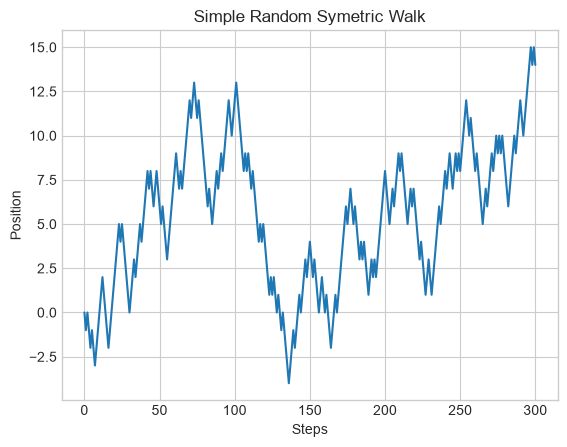

In [2]:
path = random_walk(0,300,0.5)

plt.plot(path)
plt.title("Simple Random Symetric Walk")
plt.xlabel("Steps")
plt.ylabel("Position")

Now lets simulate 20 paths with p = 0.6

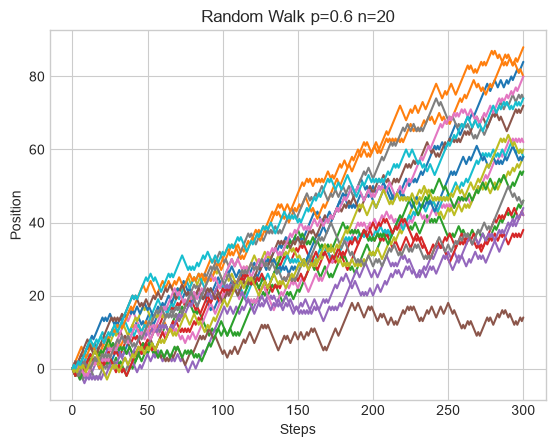

In [3]:
paths, final_positions = simulate_random_walks(20,0,300,0.6)
for i in paths:
    plt.plot(i)

plt.title("Random Walk p=0.6 n=20")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.show()

We can verify the theoretical expectation E(Xn) = X0 + n*(p-q), in our case 60 and varience 4npq of 288.

In [4]:
import numpy as np

mean: 58.7
var: 330.51


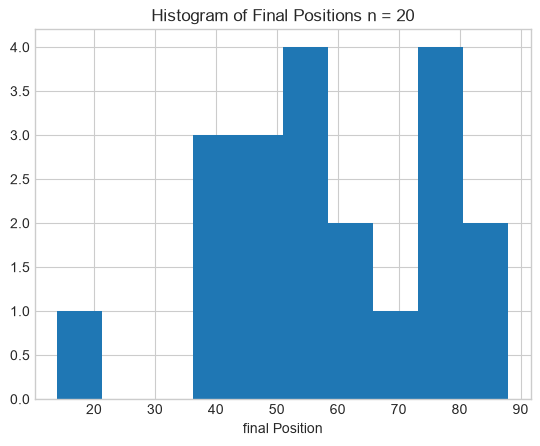

In [5]:
plt.hist(final_positions)
plt.title("Histogram of Final Positions n = 20")
plt.xlabel("final Position")

print("mean:", np.mean(final_positions))
print("var:", np.var(final_positions))

Now lets observe how the empircal expectation and varience behave as n increases.

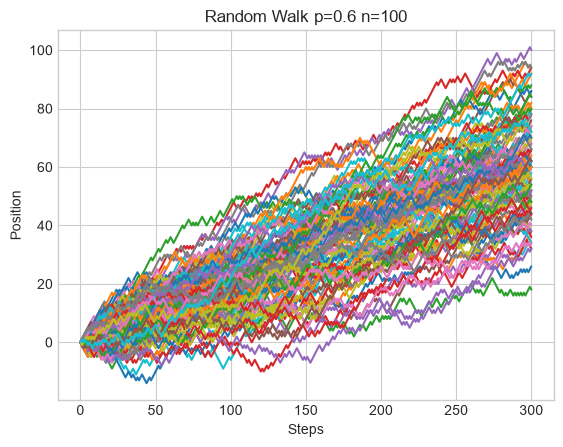

mean: 60.7
var: 300.59


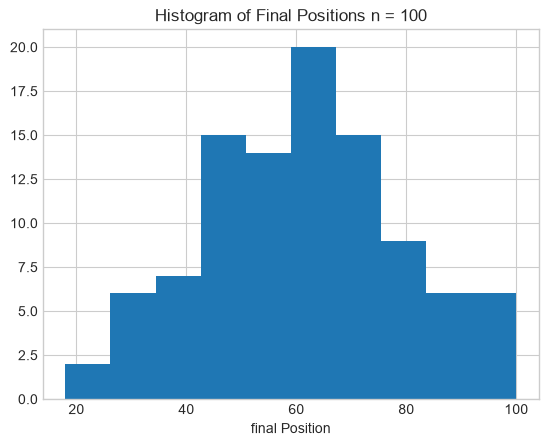

In [6]:
paths, final_positions = simulate_random_walks(100,0,300,0.6)

for i in paths:
    plt.plot(i)

plt.title("Random Walk p=0.6 n=100")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.show()

plt.hist(final_positions)
plt.title("Histogram of Final Positions n = 100")
plt.xlabel("final Position")

print("mean:", np.mean(final_positions))
print("var:", np.var(final_positions))

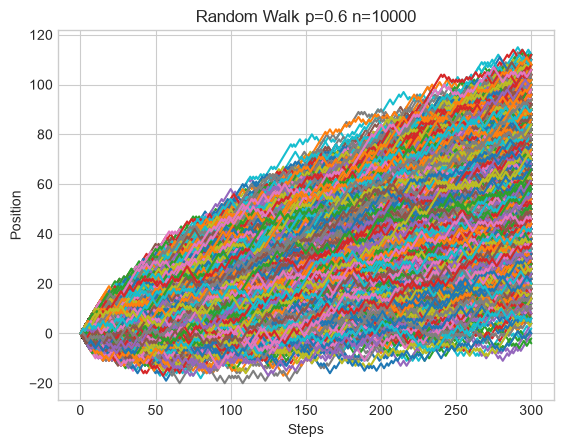

mean: 59.8264
var: 292.21466304


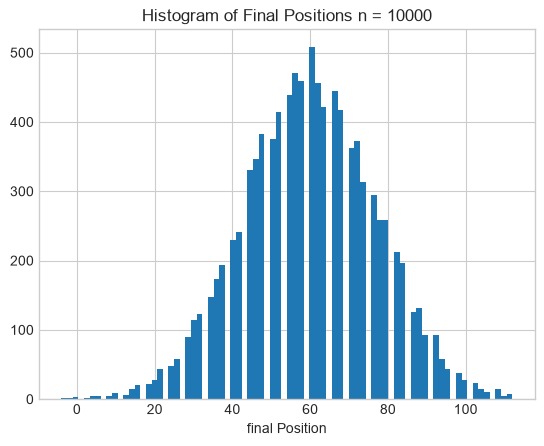

In [7]:
paths, final_positions = simulate_random_walks(10000,0,300,0.6)

for i in paths:
    plt.plot(i)

plt.title("Random Walk p=0.6 n=10000")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.show()

plt.hist(final_positions, bins=80)
plt.title("Histogram of Final Positions n = 10000")
plt.xlabel("final Position")

print("mean:", np.mean(final_positions))
print("var:", np.var(final_positions))

2. Gamblers ruin

In [8]:
%load_ext autoreload
%autoreload 2
from src.gamblers_ruin import gamblers_ruin, simulate_gamblers_ruin, run_for_n, exact_duration_pmf


Lets start by simulating a singular path starting at 20 with p = 0.5 and a barrier at 40

346 40


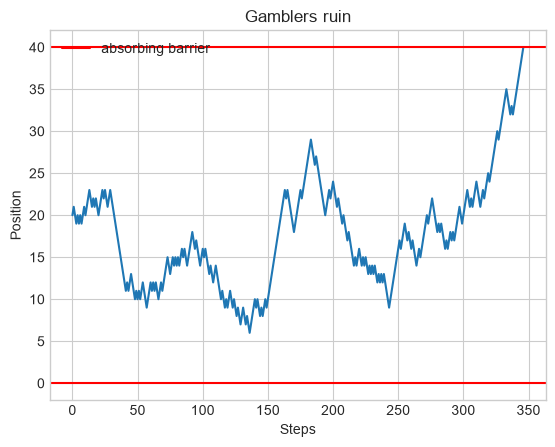

In [9]:
path, final_position, steps = gamblers_ruin(20,0.5,40)

plt.plot(path)
plt.title("Gamblers ruin")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.axhline(y=40, color = "red", label = "absorbing barrier")
plt.axhline(y=0, color = "red")
plt.legend()

print(steps, final_position)

We can estimate the expected probability of ruin by simulation multiple paths and seeing the proportion of wins against losses. We can similarly estimate the duration of the game.

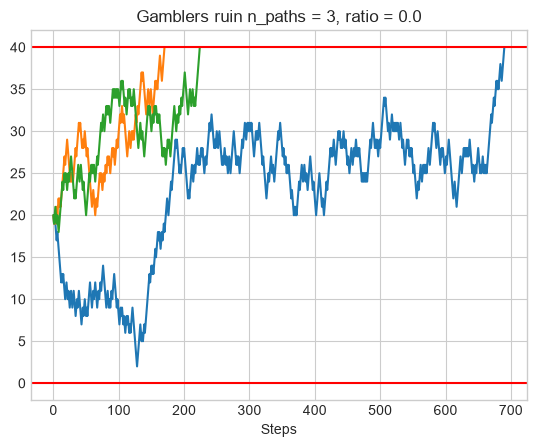

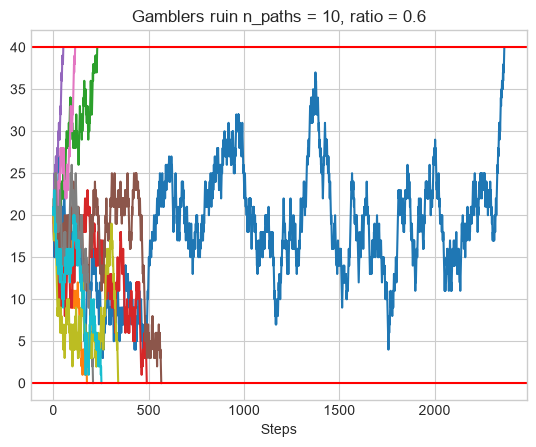

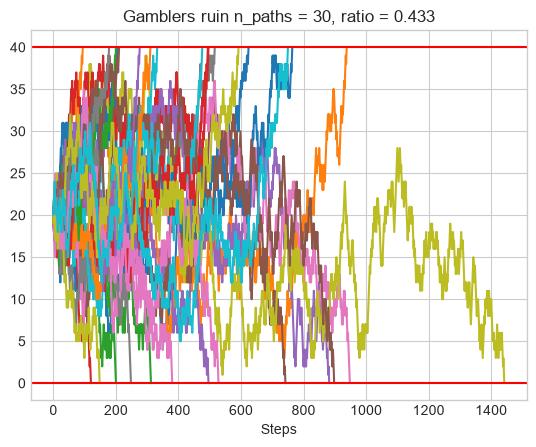

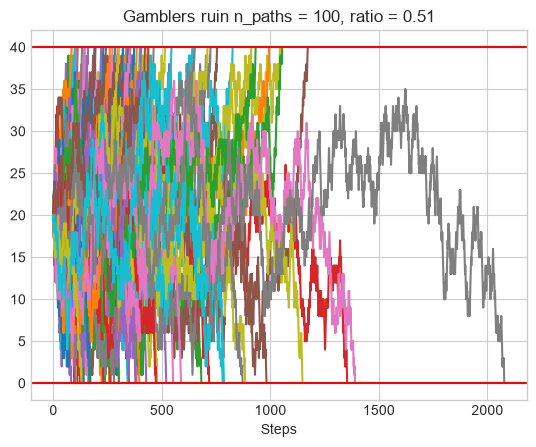

In [10]:
n_paths = [3,10,30, 100]
m = 40
for i in n_paths:
    paths, final_positions, steps = simulate_gamblers_ruin(i, 20,0.5, m)
    ratio = np.sum(np.array(final_positions) == 0)/i

    for j in paths:
        plt.plot(j)
    plt.title(f"Gamblers ruin n_paths = {i}, ratio = {round(ratio,3)}")
    plt.xlabel("Steps")
    plt.axhline(y=40, color = "red", label = "absorbing barrier")
    plt.axhline(y=0, color = "red")
    plt.show()




lets change m, p and starting positions

ratio: 0.36468


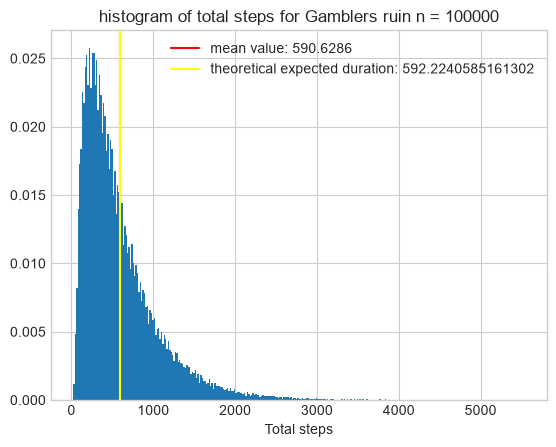

In [11]:
n_paths = 100000
m = 50
p = 0.51
a = 20
paths, final_positions, steps = simulate_gamblers_ruin(n_paths, a,p, m)

rho = (1-p)/p
expected_duration = (1/(1-2*p))*(a-m*((1-rho**a)/(1-rho**m)))

mean_duration = np.mean(steps)
median_duration = np.median(steps)

plt.hist(steps, bins=320, weights=np.ones_like(steps) / len(steps))
plt.title("histogram of total steps for Gamblers ruin n = 100000")
plt.axvline(x = mean_duration, color = "red", label = f"mean value: {mean_duration}")
plt.axvline(x = expected_duration, color = "yellow", label = f"theoretical expected duration: {expected_duration}")
plt.legend()
plt.xlabel("Total steps")

ratio = np.sum(np.array(final_positions) == 0)/n_paths
print("ratio:", ratio)

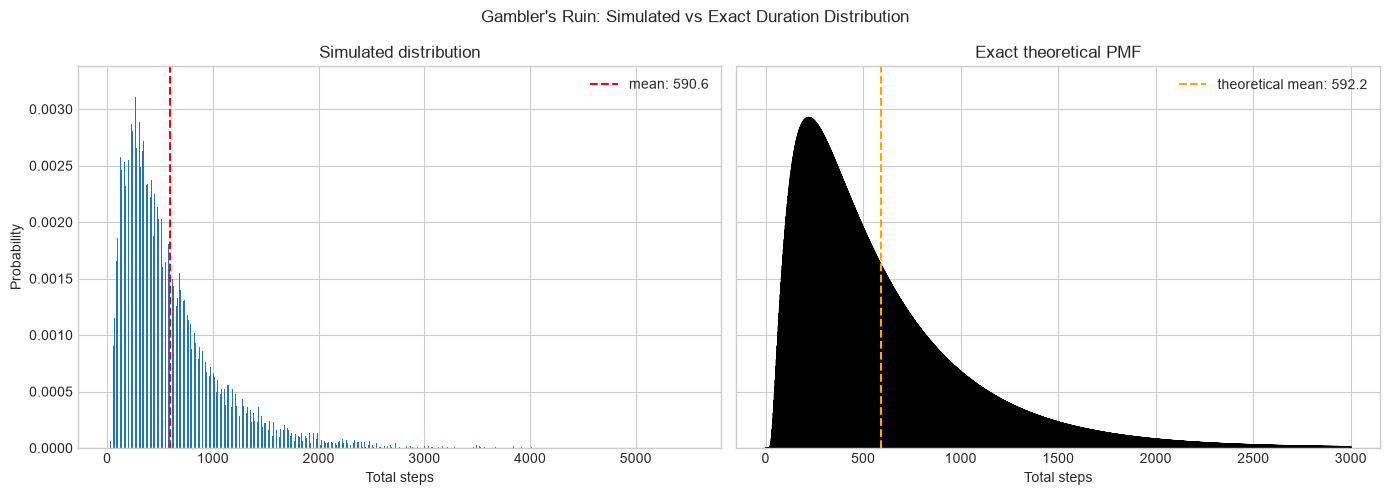

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
max_step = np.max(steps)
bins = np.arange(1, max_step + 2) - 0.5

pmf = exact_duration_pmf(a=20, m=50, p=0.51, n_max=3000)

# Left: simulated
axes[0].hist(steps, bins=bins, weights=np.ones_like(steps)/len(steps), color="tab:blue")
axes[0].axvline(mean_duration, color="red", linestyle="--", label=f"mean: {mean_duration:.1f}")
axes[0].set_title("Simulated distribution")
axes[0].set_xlabel("Total steps")
axes[0].set_ylabel("Probability")
axes[0].legend()

# Right: exact pmf
axes[1].plot(np.arange(1, len(pmf)+1), pmf, color="black")
axes[1].axvline(expected_duration, color="orange", linestyle="--", label=f"theoretical mean: {expected_duration:.1f}")
axes[1].set_title("Exact theoretical PMF")
axes[1].set_xlabel("Total steps")
axes[1].legend()

plt.suptitle("Gambler's Ruin: Simulated vs Exact Duration Distribution")
plt.tight_layout()
plt.show()

In [15]:
cdf = np.cumsum(pmf)
prob = cdf[20]
step = np.searchsorted(cdf, 0.95)
print(step, cdf[step])

1521 0.950073819094885


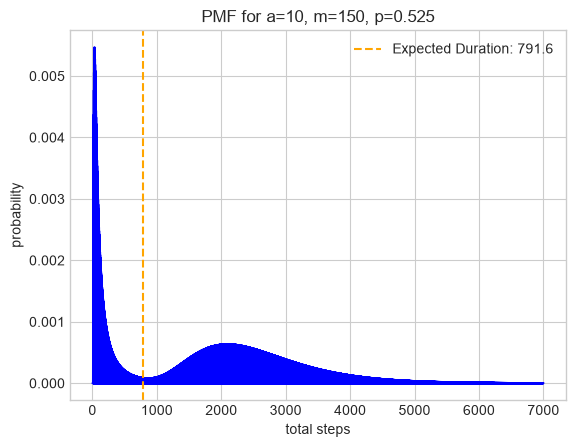

In [16]:
a=10
m=150
p=0.525
pmf = exact_duration_pmf(a, m , p, n_max=7000)

expected_duration = (1/(1-2*p))*(a-m*((1-rho**a)/(1-rho**m)))

plt.plot(np.arange(1, len(pmf)+1), pmf, color="blue")
plt.axvline(expected_duration, color="orange", linestyle="--", label=f"Expected Duration: {expected_duration:.1f}")
plt.title("PMF for a=10, m=150, p=0.525")
plt.xlabel("total steps")
plt.ylabel("probability")
plt.legend()

In [17]:
cdf = np.cumsum(pmf)
print(cdf[792])
theoretical_prob = (rho**20 - rho**m)/(1-rho**m)
split1 = 500
split2 = 1000
print(np.sum(pmf[0:split1]))
print(np.sum(pmf[split1:split2]))
print(np.sum(pmf[split2:7000]))


0.353036327369231
0.33410949338134094
0.027663830088324008
0.6375121294605146


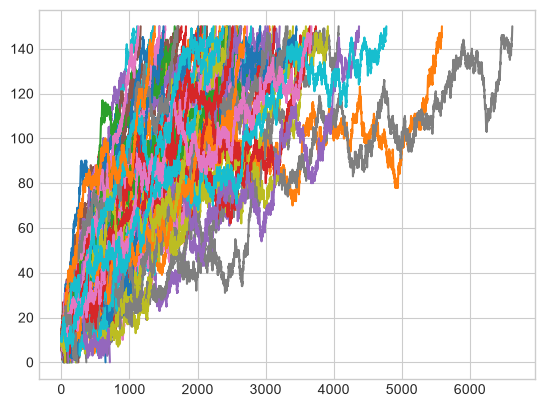

In [18]:
paths = simulate_gamblers_ruin(100, 10, 0.525, 150)[0]
for i in paths:
    plt.plot(i)

investigating how probability of ruin changes with start position and probability p

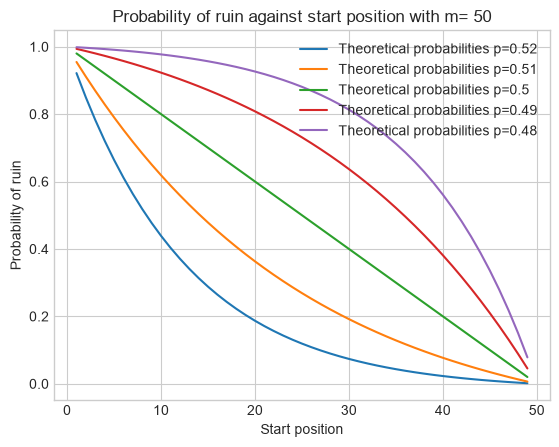

In [19]:
n_paths = 1000
named = False
m = 50
x = np.arange(1, 50)
p = [0.52, 0.51, 0.5, 0.49, 0.48]
for j in p:
    ratios = []
    rho = (1-j)/j
    if rho == 1:
        theoretical_prob = (1-x/m)
    else:
        theoretical_prob = (rho**x - rho**m)/(1-rho**m)
    plt.plot(x, theoretical_prob, label=f"Theoretical probabilities p={j}")
plt.xlabel("Start position")
plt.ylabel("Probability of ruin")
plt.title(f"Probability of ruin against start position with m= 50")
plt.legend()
plt.show()

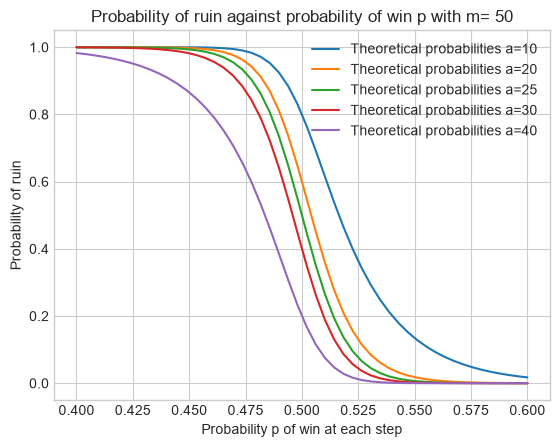

In [20]:
n_paths = 1000
named = False
a = [10, 20, 25, 30, 40]
m = 50
p = np.linspace(0.40, 0.60, 50)
for j in a:
    ratios = []
    rho = (1-p)/p
    theoretical_prob = (rho**j - rho**m)/(1-rho**m)
    plt.plot(p, theoretical_prob, label=f"Theoretical probabilities a={j}")
plt.legend()
plt.xlabel("Probability p of win at each step")
plt.ylabel("Probability of ruin")
plt.title("Probability of ruin against probability of win p with m= 50")
plt.show()

In [21]:
from concurrent.futures import ProcessPoolExecutor

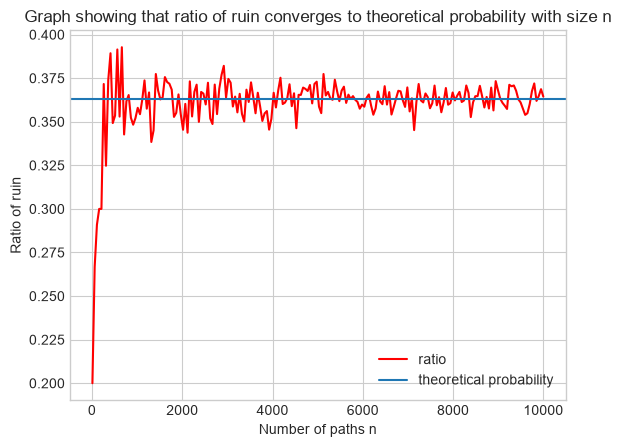

Text(0.5, 1.0, 'Associated error')

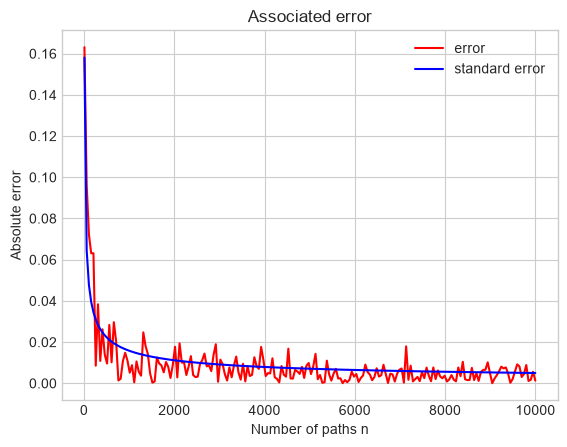

In [22]:
n_paths = np.linspace(10,10000,200).astype(int)

m = 50
p = 0.51
ratios = []
rho = (1-p)/p
theoretical_prob = (rho**20 - rho**m)/(1-rho**m)

args = [(n, 20, p, m) for n in n_paths]

with ProcessPoolExecutor() as executor:
    ratios = list(executor.map(run_for_n, args))

error = abs(np.array(ratios) - theoretical_prob)
standard_error = ((p*(1-p))/n_paths)**0.5

plt.plot(n_paths, ratios, label="ratio", color="red")
plt.axhline(y=theoretical_prob, label= "theoretical probability")
plt.legend()
plt.xlabel("Number of paths n")
plt.ylabel("Ratio of ruin")
plt.title("Graph showing that ratio of ruin converges to theoretical probability with size n")
plt.show()

plt.plot(n_paths, error, label="error", color="red")
plt.plot(n_paths, standard_error, label="standard error", color="blue")
plt.legend()
plt.xlabel("Number of paths n")
plt.ylabel("Absolute error")
plt.title("Associated error")